In [10]:
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

In [5]:
csv_path = "/Users/pit/Documents/chalmers/research-assistant/code/mtdtwa_function/csv_results/"
df_list = []
df_total = pd.DataFrame()

pattern = re.compile(r"bench_seed(\d+)_tree(\d+)_n(\d+)\.csv")

for file in os.listdir(csv_path):
    m = pattern.match(file)
    if m:
        df = pd.read_csv(os.path.join(csv_path, file))
        df["seed"] = int(m.group(1))
        df["tree_size"] = int(m.group(2))
        df_total = pd.concat([df_total, df], ignore_index=True)
        df_list.append(df)
        n_mismatches = df['match'].value_counts().get(False, 0)
        if n_mismatches > 0:
            print(f"{file}: {n_mismatches} mismatches/errors")
            for sample in df[df['match'] == False][['formula', 'acceptance', 'swa_realizable', 'ltlsynt_realizable']].itertuples(index=False):
                print(f"  Formula: {sample.formula}\n  Acceptance: {sample.acceptance}\n SWA-Result: {sample.swa_realizable}\n LTLsynth-Result: {sample.ltlsynt_realizable}\n" )

In [6]:
df = df_list[0]
print(df[df['match'] == False]['formula'].astype(str).value_counts())

Series([], Name: count, dtype: int64)


In [8]:
valid = df_total[
    (df_total["error"] == False)
    & (df_total["swa_ms"] > 0)
    & (df_total["ltlsynt_ms"] > 0)
].copy()
valid["speedup"] = valid["ltlsynt_ms"] / valid["swa_ms"]

valid["ltlsynt_ms"].describe()


count     7500.000000
mean        14.539606
std       1144.465971
min          0.026000
25%          0.119000
50%          0.187000
75%          0.387250
max      99076.300000
Name: ltlsynt_ms, dtype: float64

In [9]:
valid["swa_ms"].describe()

count    7500.000000
mean        0.095558
std         1.112563
min         0.012000
25%         0.029000
50%         0.046000
75%         0.072000
max        68.883000
Name: swa_ms, dtype: float64

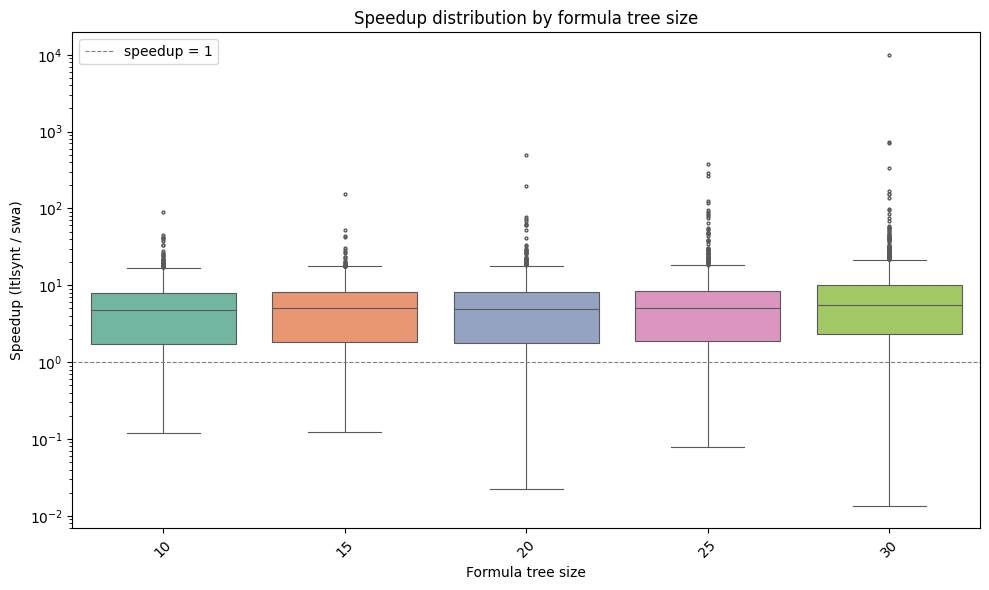

In [11]:
# keep only valid runs and compute the speedup ratio
valid = df_total[
    (df_total["error"] == False)
    & (df_total["swa_ms"] > 0)
    & (df_total["ltlsynt_ms"] > 0)
].copy()
valid["speedup"] = valid["ltlsynt_ms"] / valid["swa_ms"]

plt.figure(figsize=(10, 6))

# single boxplot of speedup per tree size — no loop, no overlap
sns.boxplot(
    data=valid,
    x="tree_size",
    y="speedup",
    hue="tree_size",      # assign hue so palette works in modern seaborn
    palette="Set2",
    legend=False,
    fliersize=2,
    linewidth=0.8,
)

plt.yscale("log")         # ratio → log scale makes >1 and <1 symmetric
plt.axhline(y=1, color="gray", linestyle="--", linewidth=0.8, label="speedup = 1")

plt.xlabel("Formula tree size")
plt.ylabel("Speedup (ltlsynt / swa)")
plt.title("Speedup distribution by formula tree size")
plt.xticks(rotation=45)   # keep crowded labels readable
plt.legend()
plt.tight_layout()
plt.show()